# Notebook 01 — Data Audit, Target Design and Initial EDA

**Project:** Design and Evaluation of a Governed Multi-Signal Drift-Aware Intervention Policy under Delayed Labels: A Google Cloud MLOps Prototype 

**Author:** Sahar Imani  
**Notebook:** 1 of 5


This notebook prepares the foundation for the rest of the project. It audits the raw Lending Club data, examines how loan outcomes mature over time, and uses that evidence to decide which cohorts can support a resolved binary target.
The output is a single interim dataset, `loan_main_target.csv`, which Notebook 02 turns into the
chronological modelling splits. 

## 1. Setup and Data Loading

The Lending Club loan dataset used in this project was obtained from [Kaggle](https://www.kaggle.com/datasets/ethon0426/lending-club-20072020q1). The raw file covers 2007 to 2020Q3.

In [1]:
# Uncomment only if the required libraries are not already installed
# %pip install -q pandas numpy matplotlib

In [2]:
# Core libraries for data handling and plots
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from pathlib import Path

In [3]:
# Load the raw Lending Club data
df = pd.read_csv("../data/raw/Loan_status_2007-2020Q3.gzip", low_memory=False)

# Print the size of the dataset
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.head()

Number of rows: 2925493
Number of columns: 142


,Unnamed: 0,id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,hardship_start_date,hardship_end_date,payment_plan_start_date,hardship_length,hardship_dpd,hardship_loan_status,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,debt_settlement_flag
0,0,1077501,5000.0,5000.0,4975.0,36 months,10.65%,162.87,B,B2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N
1,1,1077430,2500.0,2500.0,2500.0,60 months,15.27%,59.83,C,C4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N
2,2,1077175,2400.0,2400.0,2400.0,36 months,15.96%,84.33,C,C5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N
3,3,1076863,10000.0,10000.0,10000.0,36 months,13.49%,339.31,C,C1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N
4,4,1075358,3000.0,3000.0,3000.0,60 months,12.69%,67.79,B,B5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N


In [4]:
# Structure, missingness and cardinality across all raw columns
structure_summary = pd.DataFrame({"column": df.columns,
                                  "dtype": df.dtypes.astype(str).values,
                                  "missing_count": df.isna().sum().values,
                                  "missing_percent": (df.isna().mean().values * 100).round(2),
                                  "unique_values": df.nunique(dropna=True).values})

display(structure_summary.sort_values("missing_percent", ascending=False).head(30))

print("Dataset shape:", df.shape)

,column,dtype,missing_count,missing_percent,unique_values
137,hardship_loan_status,str,2782082,95.10,14
129,hardship_status,str,2781858,95.09,4
135,hardship_length,float64,2781855,95.09,4
132,hardship_start_date,str,2781855,95.09,46
130,deferral_term,float64,2781855,95.09,4
136,hardship_dpd,float64,2781856,95.09,47
134,payment_plan_start_date,str,2781855,95.09,46
127,hardship_type,str,2781855,95.09,10
128,hardship_reason,str,2781861,95.09,17
133,hardship_end_date,str,2781855,95.09,48


Dataset shape: (2925493, 142)


The raw file holds 2,925,493 loans across 142 columns. Many columns are almost entirely
missing, mostly joint-application and hardship fields that only apply to a small subset of loans.

## 2. Loan Status and Time Coverage

`loan_status` is the field the target is built from, so its distribution and the way it changes
across issue years determine which cohorts are usable.

In [5]:
# How many loans sit in each status
status_counts = df["loan_status"].value_counts(dropna=False)

# Also calculate the percentage share of each status
status_props = (df["loan_status"].value_counts(normalize=True, dropna=False) * 100).round(2)

# Combine counts and percentages into one table
status_summary = pd.DataFrame({"count": status_counts, "percent": status_props})

status_summary

,count,percent
loan_status,,
Fully Paid,1497783,51.20
Current,1031016,35.24
Charged Off,362548,12.39
Late (31-120 days),16154,0.55
In Grace Period,10028,0.34
Late (16-30 days),2719,0.09
Issued,2062,0.07
Does not meet the credit policy. Status:Fully Paid,1988,0.07
Does not meet the credit policy. Status:Charged Off,761,0.03


In [6]:
# Fresh copy to avoid fragmentation warnings when adding columns
df = df.copy()

# Parse the issue date once, so every later diagnostic uses the same field
df["issue_d"] = pd.to_datetime(df["issue_d"], format="%b-%Y", errors="coerce")
df["issue_year"] = df["issue_d"].dt.year.astype("Int64")

# Clean term once here, so all term-based diagnostics below are consistent
df["term"] = df["term"].astype(str).str.strip()

In [7]:
# Time coverage of the raw data
print("Min issue date:", df["issue_d"].min())
print("Max issue date:", df["issue_d"].max())

display(df["issue_year"].value_counts().sort_index())

Min issue date: 2007-06-01 00:00:00
Max issue date: 2020-09-01 00:00:00


issue_year
2007       603
2008      2393
2009      5281
2010     12537
2011     21721
2012     53367
2013    134814
2014    235629
2015    421095
2016    434407
2017    443579
2018    495242
2019    518107
2020    146717
Name: count, dtype: Int64

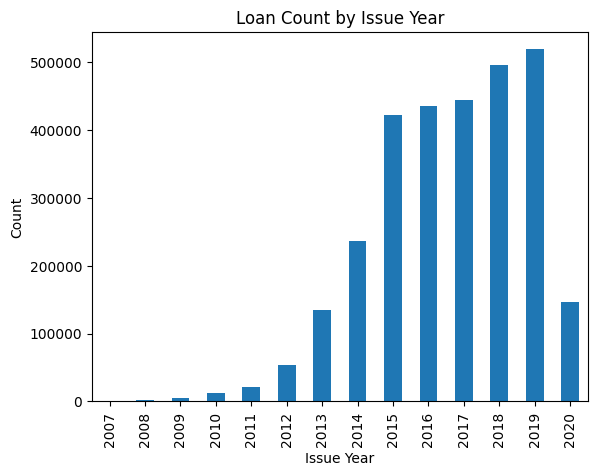

In [8]:
# Origination volume by year
df["issue_year"].value_counts().sort_index().plot(kind="bar")
plt.title("Loan Count by Issue Year")
plt.xlabel("Issue Year")
plt.ylabel("Count")
plt.show()

## 3. Cohort Maturity and Right-Censoring Checks

This is the most important diagnostic section in the notebook. The target can only be built from
loans that have reached a terminal status, so any cohort still holding a large share of `Current`
loans is unusable. The checks below establish where the study period can safely start and end.

In [9]:
# Status mix within each issue year
year_status_props = pd.crosstab(df["issue_year"], df["loan_status"], normalize="index") * 100

# Round the percentages to keep the table readable
year_status_props = year_status_props.round(2)

year_status_props

loan_status,Charged Off,Current,Default,Does not meet the credit policy. Status:Charged Off,Does not meet the credit policy. Status:Fully Paid,Fully Paid,In Grace Period,Issued,Late (16-30 days),Late (31-120 days)
issue_year,,,,,,,,,,
2007,7.46,0.00,0.00,18.74,39.64,34.16,0.00,0.00,0.00,0.00
2008,10.32,0.00,0.00,10.41,24.32,54.95,0.00,0.00,0.00,0.00
2009,11.25,0.00,0.00,2.44,8.26,78.05,0.00,0.00,0.00,0.00
2010,11.86,0.00,0.00,2.15,5.83,80.15,0.00,0.00,0.00,0.00
2011,15.18,0.00,0.00,0.00,0.00,84.82,0.00,0.00,0.00,0.00
2012,16.20,0.00,0.00,0.00,0.00,83.80,0.00,0.00,0.00,0.00
2013,15.60,0.00,0.00,0.00,0.00,84.40,0.00,0.00,0.00,0.00
2014,17.72,0.00,0.00,0.00,0.00,82.28,0.00,0.00,0.00,0.00
2015,18.93,4.16,0.00,0.00,0.00,76.73,0.07,0.00,0.02,0.09


### 3.1 Resolution by loan term

36-month and 60-month loans mature at different speeds, so they are inspected separately.

In [10]:
# 36-month loans across the full issue-year range
df_36m_all_years = df[(df["term"] == "36 months") & df["issue_year"].between(2007, 2020)].copy()

# Yearly volume and status mix
loan_counts = df_36m_all_years.groupby("issue_year").size().rename("total_36m_loans")
status_pct = pd.crosstab(df_36m_all_years["issue_year"], df_36m_all_years["loan_status"],
                         normalize="index") * 100

summary_36m = pd.concat([loan_counts, status_pct], axis=1)

# Show only the statuses that matter for maturity and right-censoring
columns_to_show = ["total_36m_loans", "Fully Paid", "Charged Off", "Current", "Default"]
valid_columns = [col for col in columns_to_show if col in summary_36m.columns]

print("36-Month Loans: Volume and Status % by Year, 2007–2020")
display(summary_36m[valid_columns].round(3))

36-Month Loans: Volume and Status % by Year, 2007–2020


,total_36m_loans,Fully Paid,Charged Off,Current,Default
issue_year,,,,,
2007,603,34.163,7.463,0.000,0.000
2008,2393,54.952,10.322,0.000,0.000
2009,5281,78.053,11.248,0.000,0.000
2010,9156,83.268,9.196,0.000,0.000
2011,14101,89.370,10.630,0.000,0.000
2012,43470,86.421,13.579,0.000,0.000
2013,100422,87.674,12.326,0.000,0.000
2014,162570,86.274,13.726,0.000,0.000
2015,283173,85.105,14.895,0.000,0.000


In [11]:
# Same view for 60-month loans, which take longer to resolve
df_60m_all_years = df[(df["term"] == "60 months") & df["issue_year"].between(2007, 2020)].copy()

loan_counts = df_60m_all_years.groupby("issue_year").size().rename("total_60m_loans")
status_pct = pd.crosstab(df_60m_all_years["issue_year"], df_60m_all_years["loan_status"],
                         normalize="index") * 100

summary_60m = pd.concat([loan_counts, status_pct], axis=1)

columns_to_show = ["total_60m_loans", "Fully Paid", "Charged Off", "Current", "Default"]
valid_columns = [col for col in columns_to_show if col in summary_60m.columns]

print("60-Month Loans: Volume and Status % by Year, 2007–2020")
display(summary_60m[valid_columns].round(3))

60-Month Loans: Volume and Status % by Year, 2007–2020


,total_60m_loans,Fully Paid,Charged Off,Current,Default
issue_year,,,,,
2010,3381,71.724,19.077,0.000,0.000
2011,7620,76.404,23.596,0.000,0.000
2012,9897,72.305,27.695,0.000,0.000
2013,34392,74.852,25.148,0.000,0.000
2014,73059,73.387,26.595,0.005,0.004
2015,137922,59.548,27.201,12.692,0.013
2016,110912,46.835,24.985,27.130,0.010
2017,123160,35.403,19.104,43.679,0.026
2018,150571,22.224,12.090,63.260,0.024


The two terms behave very differently. 36-month cohorts are effectively fully resolved up to
2017, whereas 60-month cohorts still have a substantial share of `Current` loans several years
later. This asymmetry is what makes the upper end of the study period a design decision not data availability matter.

### 3.2 Where the study period ends: the 2017 cohort

2017 is checked month by month to see how quickly the unresolved share rises, and whether it comes
mainly from 60-month loans.

In [12]:
# 2017 is the first year where unresolved loans become a problem
df_2017 = df[df["issue_year"] == 2017].copy()
df_2017["issue_month"] = df_2017["issue_d"].dt.month

monthly_status_2017 = pd.crosstab(df_2017["issue_month"], df_2017["loan_status"],
                                  normalize="index") * 100

columns_to_show = ["Fully Paid", "Charged Off", "Current"]
valid_columns = [col for col in columns_to_show if col in monthly_status_2017.columns]

print(" 2017 Overall: Status % by Month")
display(monthly_status_2017[valid_columns].round(1))

 2017 Overall: Status % by Month


loan_status,Fully Paid,Charged Off,Current
issue_month,,,
1,74.8,16.0,8.5
2,73.4,15.9,10.0
3,73.9,15.5,10.0
4,71.9,15.9,11.4
5,64.8,16.0,18.1
6,52.9,15.3,30.6
7,50.6,15.1,32.9
8,48.9,14.4,35.4
9,45.6,15.7,37.3


In [13]:
# Split the Current rate by term to show where the unresolved loans come from
current_by_month_term_2017 = (df_2017.groupby(["issue_month", "term"])["loan_status"]
                              .apply(lambda x: (x == "Current").mean() * 100)
                              .unstack())

print("2017 Current Status % by Month and Term")
display(current_by_month_term_2017.round(3))

2017 Current Status % by Month and Term


term,36 months,60 months
issue_month,,
1,0.236,34.635
2,0.308,37.209
3,0.460,38.439
4,1.482,39.059
5,9.805,40.509
6,25.942,43.176
7,29.104,43.121
8,31.842,46.074
9,33.375,45.472


### 3.3 Where the study period starts: the 2012 cohort

2012 is checked for the opposite reason. Maturity is not the concern here. I'm checking to see whether
the credit-bureau features are populated well enough to be usable, since several of them were only
introduced part-way through that year.

In [14]:
# 2012 is a candidate start year, so check both terms together
df_2012_selected_terms = df[df["term"].astype(str).str.strip().isin(["36 months", "60 months"]) &
                            (df["issue_year"] == 2012)].copy()

df_2012_selected_terms["issue_month"] = df_2012_selected_terms["issue_d"].dt.month
df_2012_selected_terms["term"] = df_2012_selected_terms["term"].astype(str).str.strip()

# Monthly volume by term
volume_by_month_term = df_2012_selected_terms.groupby(["issue_month", "term"]).size().unstack(fill_value=0)

# Features that look structurally missing in early 2012
problem_features = ["tot_coll_amt", "tot_cur_bal", "total_rev_hi_lim", "mo_sin_old_il_acct"]
features_to_check = [col for col in problem_features if col in df_2012_selected_terms.columns]

missing_by_month = (df_2012_selected_terms.groupby("issue_month")[features_to_check]
                    .apply(lambda x: x.isna().mean() * 100))

diagnostic_2012 = pd.concat([volume_by_month_term, missing_by_month], axis=1)

print("2012 Selected-Term Loans (36 and 60 months): Volume and Missingness by Month")
display(diagnostic_2012.round(1))

2012 Selected-Term Loans (36 and 60 months): Volume and Missingness by Month


,36 months,60 months,tot_coll_amt,tot_cur_bal,total_rev_hi_lim,mo_sin_old_il_acct
issue_month,,,,,,
1,2058,544,100.0,100.0,100.0,100.0
2,2083,477,100.0,100.0,100.0,100.0
3,2357,557,100.0,100.0,100.0,100.0
4,2680,550,100.0,100.0,100.0,100.0
5,2741,659,100.0,100.0,100.0,100.0
6,3048,769,100.0,100.0,100.0,100.0
7,3781,846,100.0,100.0,100.0,100.0
8,4461,958,83.2,83.2,83.2,84.2
9,5080,1007,1.3,1.3,1.3,6.8


In [15]:
# Check whether 2012 loans are mature enough for the binary target
status_2012 = (pd.crosstab(df_2012_selected_terms["issue_month"],
                           df_2012_selected_terms["loan_status"], normalize="index") * 100)

columns_to_show = ["Fully Paid", "Charged Off", "Current", "Default"]
valid_columns = [col for col in columns_to_show if col in status_2012.columns]

print("--- 2012 Selected-Term Loans (36 and 60 months): Status % by Month ---")
display(status_2012[valid_columns].round(2))

--- 2012 Selected-Term Loans (36 and 60 months): Status % by Month ---


loan_status,Fully Paid,Charged Off
issue_month,,
1,83.09,16.91
2,83.55,16.45
3,84.80,15.20
4,84.64,15.36
5,83.26,16.74
6,81.29,18.71
7,82.30,17.70
8,83.69,16.31
9,84.38,15.62


In [16]:
# Current rate by term, since 60-month loans have the longer maturity window
current_by_month_term_2012 = (df_2012_selected_terms.groupby(["issue_month", "term"])["loan_status"]
                              .apply(lambda x: (x == "Current").mean() * 100)
                              .unstack())

print("2012 Current Status % by Month and Term")
display(current_by_month_term_2012.round(3))

2012 Current Status % by Month and Term


term,36 months,60 months
issue_month,,
1,0.0,0.0
2,0.0,0.0
3,0.0,0.0
4,0.0,0.0
5,0.0,0.0
6,0.0,0.0
7,0.0,0.0
8,0.0,0.0
9,0.0,0.0


In [17]:
# Whole-year 2012 summary to support the inclusion decision
summary_2012 = (df_2012_selected_terms.groupby("term")
    .agg(total_loans=("loan_status", "size"),
         current_rate_pct=("loan_status", lambda x: (x == "Current").mean() * 100),
         fully_paid_rate_pct=("loan_status", lambda x: (x == "Fully Paid").mean() * 100),
         charged_off_rate_pct=("loan_status", lambda x: (x == "Charged Off").mean() * 100))
    .round(4)
    .reset_index())

summary_2012_overall = pd.DataFrame({
    "term": ["All selected terms"],
    "total_loans": [len(df_2012_selected_terms)],
    "current_rate_pct": [(df_2012_selected_terms["loan_status"].eq("Current").mean() * 100).round(4)],
    "fully_paid_rate_pct": [(df_2012_selected_terms["loan_status"].eq("Fully Paid").mean() * 100).round(2)],
    "charged_off_rate_pct": [(df_2012_selected_terms["loan_status"].eq("Charged Off").mean() * 100).round(2)]})

summary_2012 = pd.concat([summary_2012, summary_2012_overall], ignore_index=True)

display(summary_2012)

,term,total_loans,current_rate_pct,fully_paid_rate_pct,charged_off_rate_pct
0,36 months,43470,0.0,86.4205,13.5795
1,60 months,9897,0.0,72.3047,27.6953
2,All selected terms,53367,0.0,83.8000,16.2000


2012 is mature enough on its own terms, but several credit-bureau features are structurally
missing for part of the year. Including it would mean either dropping those features for every
cohort or accepting an availability break inside the reference period, and neither is attractive
when 2013 provides a clean baseline. The study period therefore runs from 2013 to 2016. 2012 is
excluded for feature availability, 2017 onwards for maturity.

In [18]:
# Resolution rate by year, as a diagnostic only
resolved_statuses = ["Fully Paid", "Charged Off", "Default"]

resolved_by_year = (df.assign(is_resolved_main=df["loan_status"].isin(resolved_statuses))
    .groupby("issue_year")["is_resolved_main"]
    .mean()
    .mul(100)
    .round(2))

display(resolved_by_year)

issue_year
2007     41.63
2008     65.27
2009     89.30
2010     92.02
2011    100.00
2012    100.00
2013    100.00
2014    100.00
2015     95.66
2016     92.79
2017     70.87
2018     39.81
2019     14.55
2020      2.92
Name: is_resolved_main, dtype: float64

## 4. Target Design and Modelling Sample

`loan_status` mixes terminal outcomes with intermediate servicing states, so the binary target is
built only from loans that have reached a final resolution.

The sample keeps both 36-month and 60-month loans from 2013 to 2016. Including both terms gives a
broader and more representative credit-risk population, and `term` is retained so cohort composition
can be checked later. 

The target is:

- Good loan (0) = Fully Paid
- Bad loan (1) = Charged Off or Default

Excluded from the target: `Current`, `Issued`, `In Grace Period`, `Late (16-30 days)`,
`Late (31-120 days)`, both "Does not meet the credit policy" statuses, and missing loan statuses.
The result is a resolved-outcome sample, which carries the maturity limitation discussed at the end
of this section.

In [19]:
# Study period and loan terms for the main sample
valid_years = [2013, 2014, 2015, 2016]
valid_terms = ["36 months", "60 months"]

# Term was already cleaned in Section 2; repeated here so this cell stands alone
df["term"] = df["term"].astype(str).str.strip()

In [20]:
is_valid_year = df["issue_year"].isin(valid_years)
is_valid_term = df["term"].isin(valid_terms)

df_selected_terms = df.loc[is_valid_year & is_valid_term].copy()

print("Selected-term dataset shape:", df_selected_terms.shape)
print("Included terms:", sorted(df_selected_terms["term"].unique()))
print("Included years:", sorted(df_selected_terms["issue_year"].dropna().astype(int).unique()))

Selected-term dataset shape: (1225945, 143)
Included terms: ['36 months', '60 months']
Included years: [np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016)]


In [21]:
# Only terminal statuses can support a binary outcome
target_status_map = {"Fully Paid": 0, "Charged Off": 1, "Default": 1}

df_main = df_selected_terms[df_selected_terms["loan_status"].isin(target_status_map.keys())].copy()
print("Resolved-outcome dataset shape:", df_main.shape)

display(df_main["loan_status"].value_counts())

Resolved-outcome dataset shape: (1176374, 143)


loan_status
Fully Paid     954805
Charged Off    221476
Default            93
Name: count, dtype: int64

In [22]:
# Build the binary target: 0 = good loan, 1 = bad loan
df_main["target_bad_loan"] = df_main["loan_status"].map(target_status_map).astype(int)

print("Final modelling dataset shape:", df_main.shape)
print("Included terms:", sorted(df_main["term"].unique()))
print("Included years:", sorted(df_main["issue_year"].dropna().astype(int).unique()))

Final modelling dataset shape: (1176374, 144)
Included terms: ['36 months', '60 months']
Included years: [np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016)]


In [23]:
# Remaining observations by year, term and status
status_counts = pd.crosstab([df_main["issue_year"], df_main["term"]], df_main["loan_status"])

display(status_counts)

loan_status           Charged Off  Default  Fully Paid
issue_year term                                       
2013       36 months        12378        0       88044
           60 months         8649        0       25743
2014       36 months        22315        0      140255
           60 months        19430        3       53616
2015       36 months        42178        0      240995
           60 months        37516       18       82130
2016       36 months        51299       61      272076
           60 months        27711       11       51946

In [24]:
# How much of each cohort survives the resolved-status filter
selected_counts = df_selected_terms.groupby(["issue_year", "term"]).size().rename("selected_loans")
resolved_counts = df_main.groupby(["issue_year", "term"]).size().rename("resolved_loans")

resolved_rate_by_term = pd.concat([selected_counts, resolved_counts], axis=1).fillna(0).reset_index()

resolved_rate_by_term["resolved_rate_percent"] = (resolved_rate_by_term["resolved_loans"] /
                                                  resolved_rate_by_term["selected_loans"] * 100).round(2)

display(resolved_rate_by_term)

,issue_year,term,selected_loans,resolved_loans,resolved_rate_percent
0,2013,36 months,100422,100422,100.00
1,2013,60 months,34392,34392,100.00
2,2014,36 months,162570,162570,100.00
3,2014,60 months,73059,73049,99.99
4,2015,36 months,283173,283173,100.00
5,2015,60 months,137922,119664,86.76
6,2016,36 months,323495,323436,99.98
7,2016,60 months,110912,79668,71.83


36-month cohorts stay at or above 99.98 per cent resolved throughout. 60-month cohorts fall away
sharply: 86.76 per cent in 2015 and 71.83 per cent in 2016. Later 60-month cohorts therefore enter
the study only if they resolved early, which biases them towards early charge-offs and early
payoffs.

In [25]:
# Final target distribution by year and term
target_summary_by_term = (df_main.groupby(["issue_year", "term"])
    .agg(total_loans=("target_bad_loan", "size"),
         good_loans=("target_bad_loan", lambda x: (x == 0).sum()),
         bad_loans=("target_bad_loan", "sum"),
         bad_loan_rate=("target_bad_loan", "mean")))

target_summary_by_term["bad_loan_rate"] = (target_summary_by_term["bad_loan_rate"] * 100).round(2)

display(target_summary_by_term)

total_loans  good_loans  bad_loans  bad_loan_rate
issue_year term                                                        
2013       36 months       100422       88044      12378          12.33
           60 months        34392       25743       8649          25.15
2014       36 months       162570      140255      22315          13.73
           60 months        73049       53616      19433          26.60
2015       36 months       283173      240995      42178          14.89
           60 months       119664       82130      37534          31.37
2016       36 months       323436      272076      51360          15.88
           60 months        79668       51946      27722          34.80

In [26]:
# Year-level summary, reused by the plots below
target_summary = (df_main.groupby("issue_year")
    .agg(total_loans=("target_bad_loan", "size"),
         good_loans=("target_bad_loan", lambda x: (x == 0).sum()),
         bad_loans=("target_bad_loan", "sum"),
         bad_loan_rate=("target_bad_loan", "mean")))

target_summary["bad_loan_rate"] = (target_summary["bad_loan_rate"] * 100).round(2)

display(target_summary)

,total_loans,good_loans,bad_loans,bad_loan_rate
issue_year,,,,
2013,134814,113787,21027,15.60
2014,235619,193871,41748,17.72
2015,402837,323125,79712,19.79
2016,403104,324022,79082,19.62


In [27]:
# Spot-check that the target lines up with the underlying status
display(df_main[["issue_d", "issue_year", "term", "loan_status", "target_bad_loan"]].head(10))

,issue_d,issue_year,term,loan_status,target_bad_loan
42536,2013-12-01,2013,36 months,Fully Paid,0
42537,2013-12-01,2013,36 months,Fully Paid,0
42538,2013-12-01,2013,36 months,Fully Paid,0
42539,2013-12-01,2013,36 months,Fully Paid,0
42540,2013-12-01,2013,36 months,Fully Paid,0
42541,2013-12-01,2013,36 months,Fully Paid,0
42542,2013-12-01,2013,36 months,Fully Paid,0
42543,2013-12-01,2013,36 months,Fully Paid,0
42544,2013-12-01,2013,36 months,Fully Paid,0
42545,2013-12-01,2013,36 months,Fully Paid,0


`Late (31-120 days)` is excluded even though it signals repayment distress, because the loan
has not reached a terminal state.

**Maturity limitation.** The modelling sample is a resolved-outcome sample. Because 60-month loans
take longer to reach a terminal status, later 60-month cohorts are under-represented unless they
resolved early, so the resolved 60-month sample is weighted towards early charge-offs and early
payoffs. Part of the rise in bad-loan rate across 2013–2016 may therefore reflect this composition
change rather than genuine deterioration in borrower quality.

## 5. Target Trends Across the Study Period

The final view is how the bad-loan rate moves across the four study years, since this is the
portfolio-level shift the monitoring framework in Notebook 04 later has to detect.

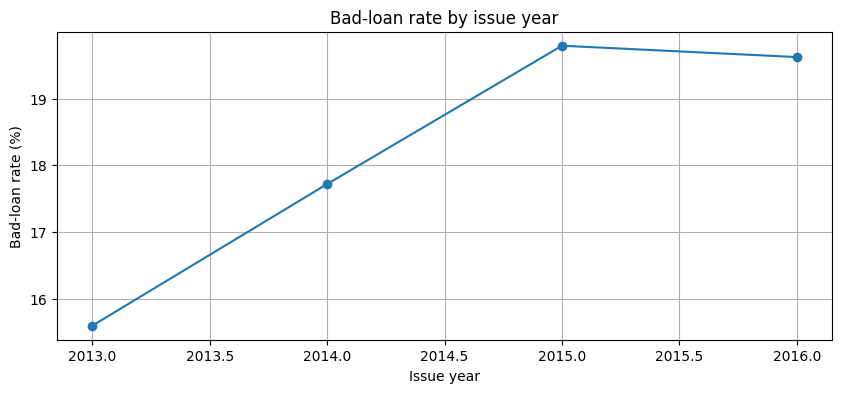

In [28]:
# Bad-loan rate by year
target_summary["bad_loan_rate"].plot(marker="o", figsize=(10, 4))

plt.title("Bad-loan rate by issue year")
plt.xlabel("Issue year")
plt.ylabel("Bad-loan rate (%)")
plt.grid(True)
plt.show()

In [29]:
# Volume and bad-loan rate together, to show risk rising as origination grows
yearly_summary = (df_main.groupby("issue_year")["target_bad_loan"]
                  .agg(total_loans="count", bad_loans="sum")
                  .reset_index())

yearly_summary["bad_loan_rate"] = (yearly_summary["bad_loans"] / yearly_summary["total_loans"] * 100).round(2)
yearly_summary["issue_year"] = yearly_summary["issue_year"].astype(int).astype(str)

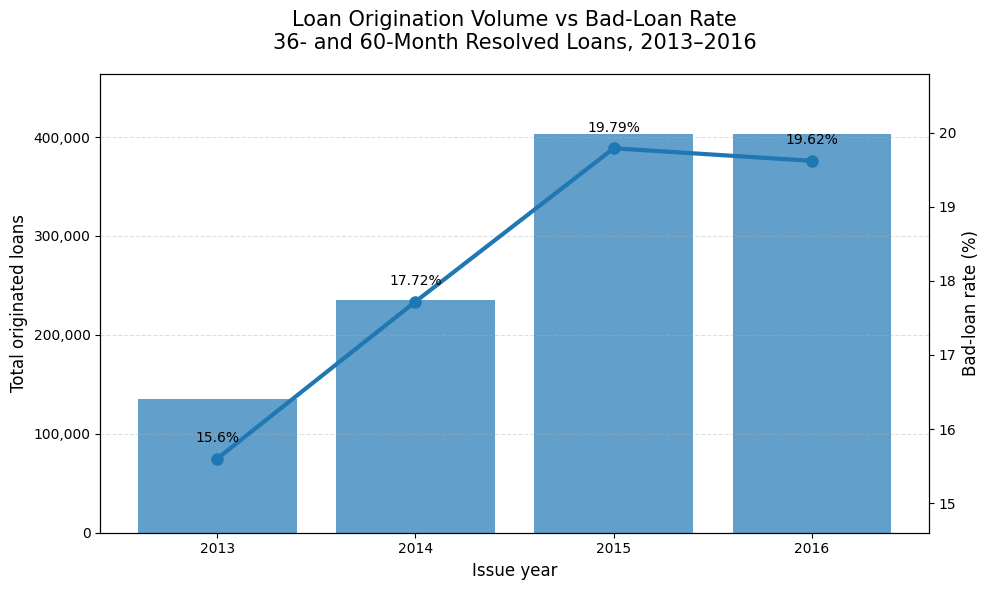

In [30]:
fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.bar(yearly_summary["issue_year"], yearly_summary["total_loans"], alpha=0.7)
ax1.set_xlabel("Issue year", fontsize=12,)
ax1.set_ylabel("Total originated loans", fontsize=12)
ax1.yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))
ax1.set_ylim(0, yearly_summary["total_loans"].max() * 1.15)
ax1.grid(axis="y", linestyle="--", alpha=0.4)

ax2 = ax1.twinx()
ax2.plot(yearly_summary["issue_year"], yearly_summary["bad_loan_rate"], marker="o", linewidth=3, markersize=8)
ax2.set_ylabel("Bad-loan rate (%)", fontsize=12)
ax2.set_ylim(yearly_summary["bad_loan_rate"].min() - 1, yearly_summary["bad_loan_rate"].max() + 1)

for i, rate in enumerate(yearly_summary["bad_loan_rate"]):
    ax2.annotate(f"{rate}%", (i, rate), textcoords="offset points", xytext=(0, 12), ha="center",
                 fontsize=10)

plt.title("Loan Origination Volume vs Bad-Loan Rate\n36- and 60-Month Resolved Loans, 2013–2016",
          fontsize=15, pad=18)
plt.tight_layout()
plt.show()

The realised bad-loan rate rises from 15.60 per cent in 2013 to 19.79 per cent in 2015 before
levelling at 19.62 per cent in 2016, while origination volume roughly triples.

## 6. Export for Notebook 02

In [31]:
# Save the resolved-outcome dataset for Notebook 02
interim_path = Path("../data/interim/loan_main_target.csv")
interim_path.parent.mkdir(parents=True, exist_ok=True)

df_main.to_csv(interim_path, index=False)

print("Saved interim dataset to:", interim_path)
print("Exported shape:", df_main.shape)

Saved interim dataset to: ../data/interim/loan_main_target.csv
Exported shape: (1176374, 144)
